In [2]:
import numpy as np
import healpy as hp

folder = "/hydrarepo/xluo/circles-in-the-sky/Planck_mask_sweep"
methods = ["commander", "nilc", "sevem", "smica"]
sigma = {}

for width in [80, 10]:
    maps = []

    for method in methods:
        T = hp.read_map(f"{folder}/COM_CMB_IQU-{method}_2048_R3.00_full.fits") * 1e6
        T_smooth = hp.smoothing(T, fwhm=np.deg2rad(np.sqrt(width**2 - 5**2) / 60))
        maps.append(T_smooth)

    mean = np.mean(maps, axis=0)
    sigma[width] = np.std(maps, axis=0)

    del maps


In [3]:

t80 = [3, 5, 10, 20, 50, 100]
mask80 = {}

for a in t80:
    mask80[a] = (sigma[80] < a).astype(float)

    print(a, mask80[a].mean())


3 0.6181159814198812
5 0.9080894788106283
10 0.9573779106140137
20 0.9778281648953756
50 0.9904685815175375
100 0.9956134160359701


In [4]:

mask80_smooth = {}

for a in t80:
    smoothed = hp.smoothing(mask80[a], fwhm=np.deg2rad(10))
    mask80_smooth[a] = (smoothed >= 0.5).astype(float)

    print(a, mask80_smooth[a].mean())


3 0.6277871330579122
5 0.9470139344533285
10 0.9858591556549072
20 0.9977368315060934
50 1.0
100 1.0


In [5]:
from pathlib import Path

t10 = [10, 20, 50, 100, 200]
Path("masks").mkdir(exist_ok=True)

for b in t10:
    mask10 = (sigma[10] < b).astype(float)

    for a in t80:
        mask2048 = mask80_smooth[a] * mask10
        mask256 = (hp.ud_grade(mask2048, 256) >= 0.5).astype(float)

        print(a, b, "f_sky =", mask256.mean())

        hp.write_map(
            f"masks/mask_80_{a}_10_{b}_nside256.fits",
            mask256,
            overwrite=True
        )


setting the output map dtype to [dtype('float64')]


3 10 f_sky = 0.6240399678548177


setting the output map dtype to [dtype('float64')]


5 10 f_sky = 0.9268150329589844


setting the output map dtype to [dtype('float64')]


10 10 f_sky = 0.9454612731933594


... (50 outputs left out)

setting the output map dtype to [dtype('float64')]


50 200 f_sky = 0.9977467854817709


setting the output map dtype to [dtype('float64')]


100 200 f_sky = 0.9977467854817709


In [7]:
from pathlib import Path

out = Path(folder) / "masks"
out.mkdir(exist_ok=True)

for b in t10:
    mask10 = sigma[10] < b

    for a in t80:
        mask2048 = mask80_smooth[a].astype(bool) & mask10
        mask256 = hp.ud_grade(mask2048.astype(float), 256) >= 0.5

        fsky = mask256.mean()

        hp.write_map(
            out / f"mask_80_{a}_10_{b}_fsky{fsky:.4f}_nside256.fits",
            mask256.astype(np.uint8),
            dtype=np.uint8,
            overwrite=True
        )

        print(f"80'={a}, 10'={b}, f_sky={fsky:.4f}")

80'=3, 10'=10, f_sky=0.6240
80'=5, 10'=10, f_sky=0.9268
80'=10, 10'=10, f_sky=0.9455
80'=20, 10'=10, f_sky=0.9467
80'=50, 10'=10, f_sky=0.9467
80'=100, 10'=10, f_sky=0.9467
80'=3, 10'=20, f_sky=0.6265
80'=5, 10'=20, f_sky=0.9399
80'=10, 10'=20, f_sky=0.9701
80'=20, 10'=20, f_sky=0.9742
80'=50, 10'=20, f_sky=0.9743
80'=100, 10'=20, f_sky=0.9743
80'=3, 10'=50, f_sky=0.6275
80'=5, 10'=50, f_sky=0.9447
80'=10, 10'=50, f_sky=0.9805
80'=20, 10'=50, f_sky=0.9883
80'=50, 10'=50, f_sky=0.9888
80'=100, 10'=50, f_sky=0.9888
80'=3, 10'=100, f_sky=0.6278
80'=5, 10'=100, f_sky=0.9462
80'=10, 10'=100, f_sky=0.9839
80'=20, 10'=100, f_sky=0.9936
80'=50, 10'=100, f_sky=0.9946
80'=100, 10'=100, f_sky=0.9946
80'=3, 10'=200, f_sky=0.6278
80'=5, 10'=200, f_sky=0.9467
80'=10, 10'=200, f_sky=0.9852
80'=20, 10'=200, f_sky=0.9961
80'=50, 10'=200, f_sky=0.9977
80'=100, 10'=200, f_sky=0.9977


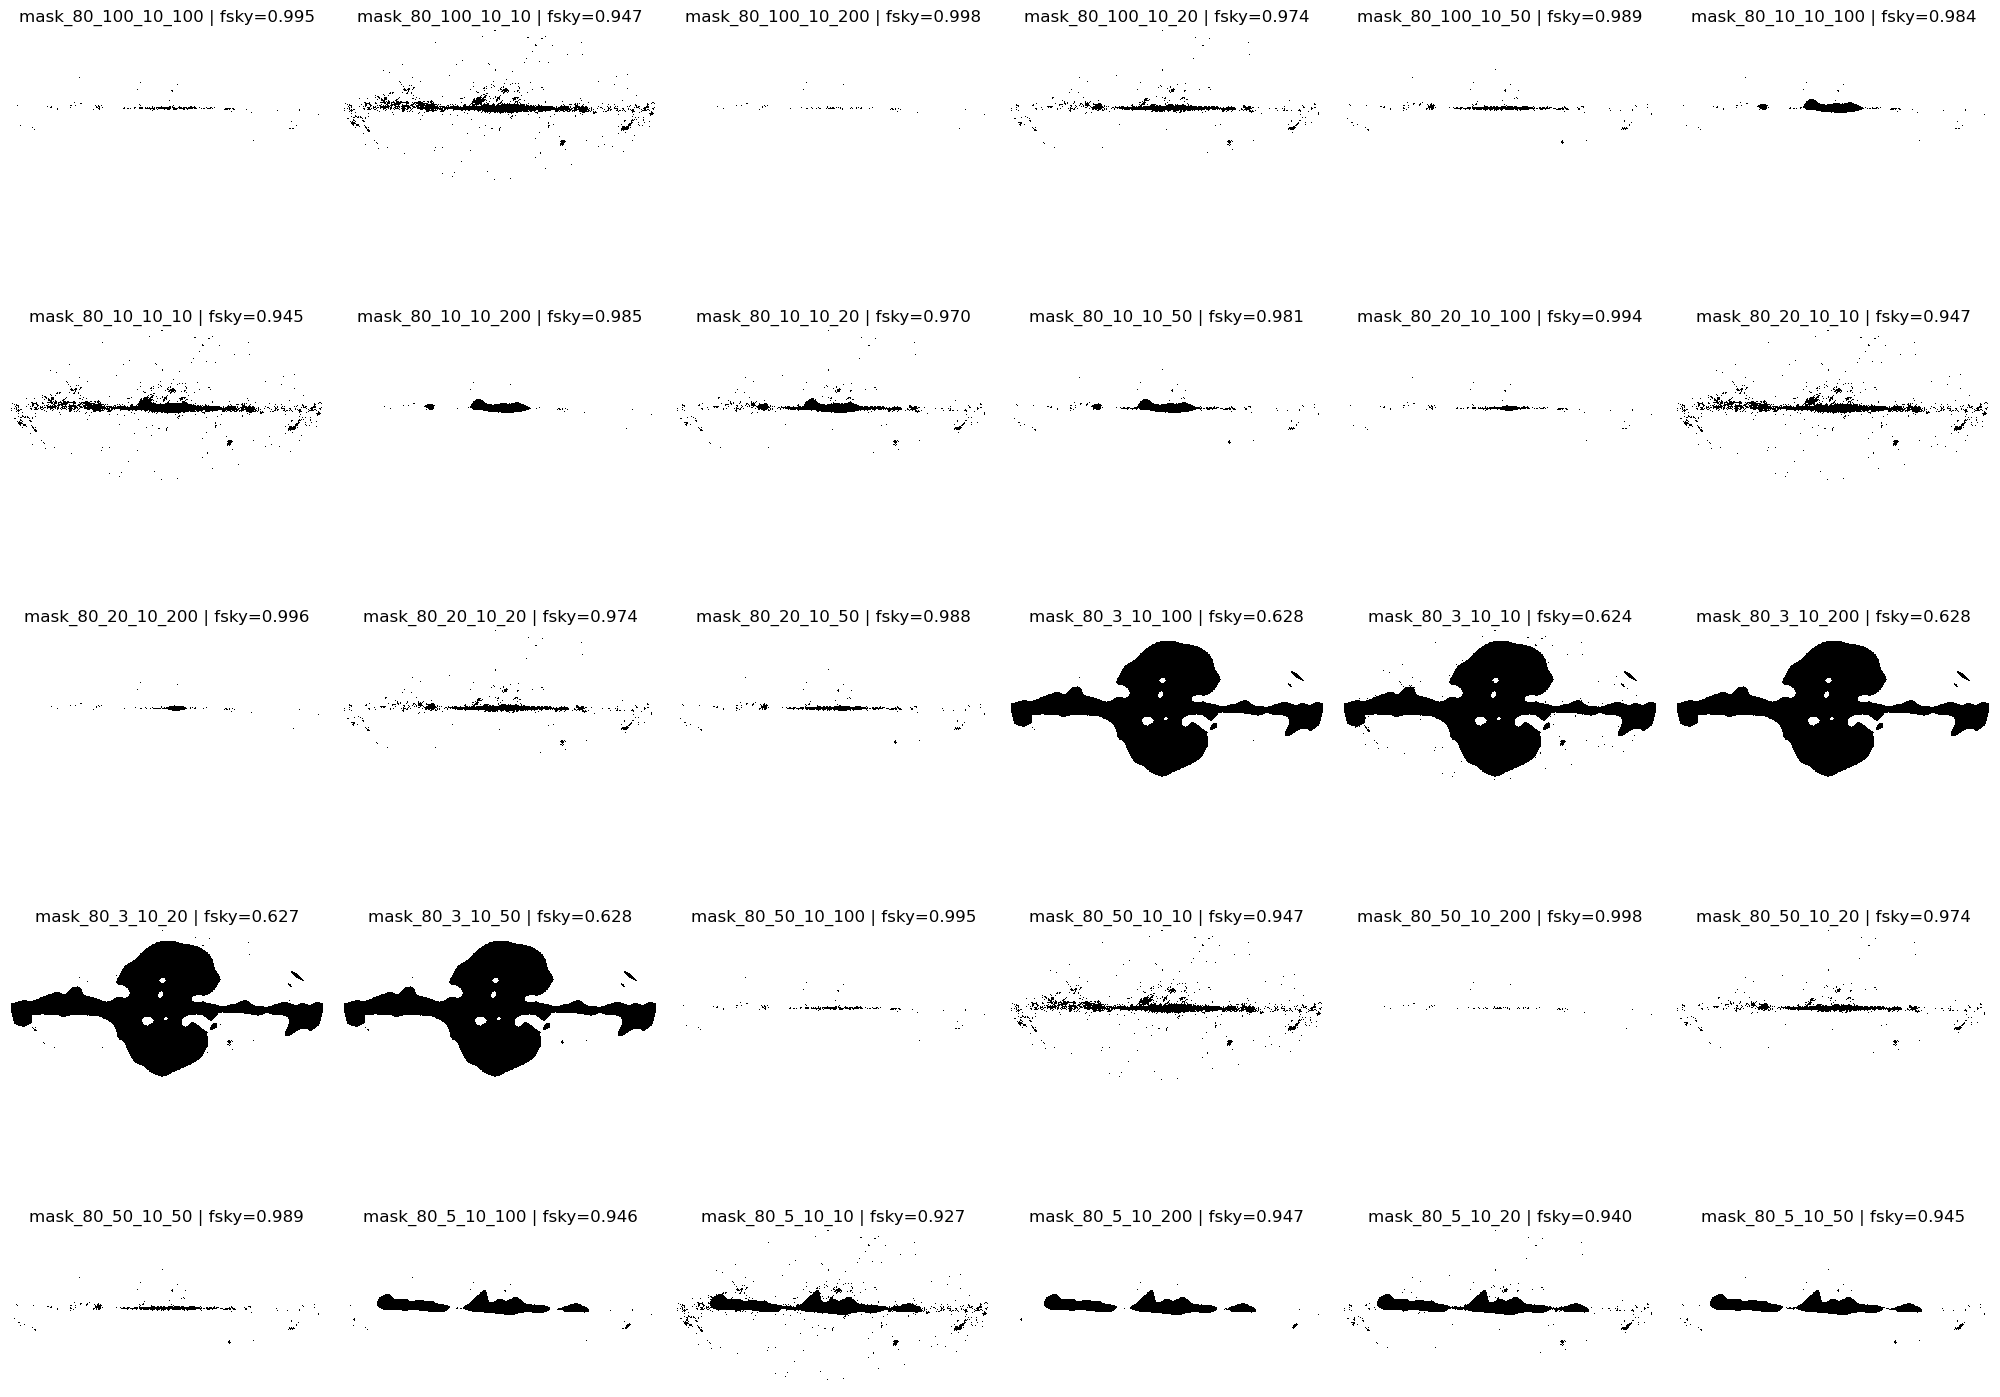

In [8]:
import matplotlib.pyplot as plt

files = sorted(out.glob("mask_*_fsky*_nside256.fits"))

fig = plt.figure(figsize=(20, 15))

for i, file in enumerate(files, 1):
    mask = hp.read_map(file)

    hp.mollview(
        mask, fig=fig.number, sub=(5, 6, i),
        title=f"{file.stem.split('_fsky')[0]} | fsky={mask.mean():.3f}",
        min=0, max=1, cmap="gray",
        cbar=False, notext=True
    )

plt.show()

In [9]:
import numpy as np
import healpy as hp
from pathlib import Path
import matplotlib.pyplot as plt
import csv

folder = "/hydrarepo/xluo/circles-in-the-sky/Planck_mask_sweep"
methods = ["commander", "nilc", "sevem", "smica"]
sigma = {}

for width in [80, 10]:
    maps = []
    for method in methods:
        T = hp.read_map(f"{folder}/COM_CMB_IQU-{method}_2048_R3.00_full.fits") * 1e6
        maps.append(hp.smoothing(T, fwhm=np.deg2rad(np.sqrt(width**2 - 5**2) / 60)))
    sigma[width] = np.std(maps, axis=0)
    del maps

print('Input NSIDE:', hp.get_nside(sigma[80]))

Input NSIDE: 2048


In [ ]:
B10 = 200
NSIDE_OUT = 256
OUT = Path('masks_fsky_078_to_099')
OUT.mkdir(exist_ok=True)

mask10 = (sigma[10] < B10).astype(float)
cache = {}  # threshold a -> (actual f_sky, binary NSIDE-256 mask)

def evaluate(a):
    a = float(a)
    if a not in cache:
        mask80 = (sigma[80] < a).astype(float)
        mask80_smooth = (hp.smoothing(mask80, fwhm=np.deg2rad(10)) >= 0.5).astype(float)
        m = (hp.ud_grade(mask80_smooth * mask10, NSIDE_OUT) >= 0.5).astype(np.uint8)
        cache[a] = (float(m.mean()), m)
    return cache[a][0]

# Confirm that the bracket covers the desired f_sky interval.
lo_a, hi_a = 3.0, 50.0
print('f_sky at a=3: ', evaluate(lo_a))
print('f_sky at a=50:', evaluate(hi_a))
assert evaluate(lo_a) < 0.78 and evaluate(hi_a) > 0.99, 'Adjust threshold bracket.' 

f_sky at a=3:  0.6278165181477865
f_sky at a=50: 0.9977467854817709


In [11]:
# Search a threshold for each target f_sky, reusing previously evaluated masks.
# Use 0.781 .. 0.989 so small discretization errors still keep outputs in [0.78, 0.99].
targets = np.linspace(0.781, 0.989, 30)
tol = 0.001


def find_threshold(target, max_steps=18):
    for _ in range(max_steps):
        # From all already tested thresholds, select the closest bracket in f_sky.
        items = sorted((a, v[0]) for a, v in cache.items())
        lower = [(a, f) for a, f in items if f <= target]
        upper = [(a, f) for a, f in items if f >= target]
        a0, f0 = lower[-1]
        a1, f1 = upper[0]
        if min(abs(f0-target), abs(f1-target)) <= tol or a1 - a0 < 1e-7:
            break
        evaluate((a0 + a1) / 2)
    candidates = [(abs(f-target), a, f) for a, (f, m) in cache.items()
                  if 0.78 <= f <= 0.99]
    _, a_best, f_best = min(candidates)
    return a_best, f_best

rows = []
for i, target in enumerate(targets):
    a, f = find_threshold(target)
    # All maps are strictly binary and have NSIDE 256.
    m = cache[a][1]
    filename = f'mask_{i+1:02d}_fsky_{f:.4f}_nside256.fits'
    hp.write_map(str(OUT / filename), m.astype(np.float32), overwrite=True)
    rows.append((i+1, float(target), a, f, filename))
    print(f'{i+1:02d}/30  target={target:.3f}  actual={f:.4f}  a80={a:.6f} μK  {filename}')

with (OUT / 'mask_catalog.csv').open('w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(['index','target_fsky','a80_uK','actual_fsky','filename'])
    writer.writerows(rows)

if len({row[4] for row in rows}) != 30:
    print('Warning: repeated output names.')
print('Saved 30 binary NSIDE-256 FITS masks to:', OUT.resolve())

setting the output map dtype to [dtype('float32')]


01/30  target=0.781  actual=0.7802  a80=3.539307 μK  mask_01_fsky_0.7802_nside256.fits


setting the output map dtype to [dtype('float32')]


02/30  target=0.788  actual=0.7881  a80=3.562256 μK  mask_02_fsky_0.7881_nside256.fits


setting the output map dtype to [dtype('float32')]


03/30  target=0.795  actual=0.7949  a80=3.585205 μK  mask_03_fsky_0.7949_nside256.fits


... (36 outputs left out)

setting the output map dtype to [dtype('float32')]
setting the output map dtype to [dtype('float32')]


28/30  target=0.975  actual=0.9749  a80=7.773438 μK  mask_28_fsky_0.9749_nside256.fits
29/30  target=0.982  actual=0.9816  a80=8.875000 μK  mask_29_fsky_0.9816_nside256.fits


setting the output map dtype to [dtype('float32')]


30/30  target=0.989  actual=0.9895  a80=13.281250 μK  mask_30_fsky_0.9895_nside256.fits
Saved 30 binary NSIDE-256 FITS masks to: /hydrarepo/xluo/circles-in-the-sky/src/masks_fsky_078_to_099


/tmp/ipykernel_724763/2779371540.py:27: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  mask = hp.read_map(file, verbose=False)
/tmp/ipykernel_724763/2779371540.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


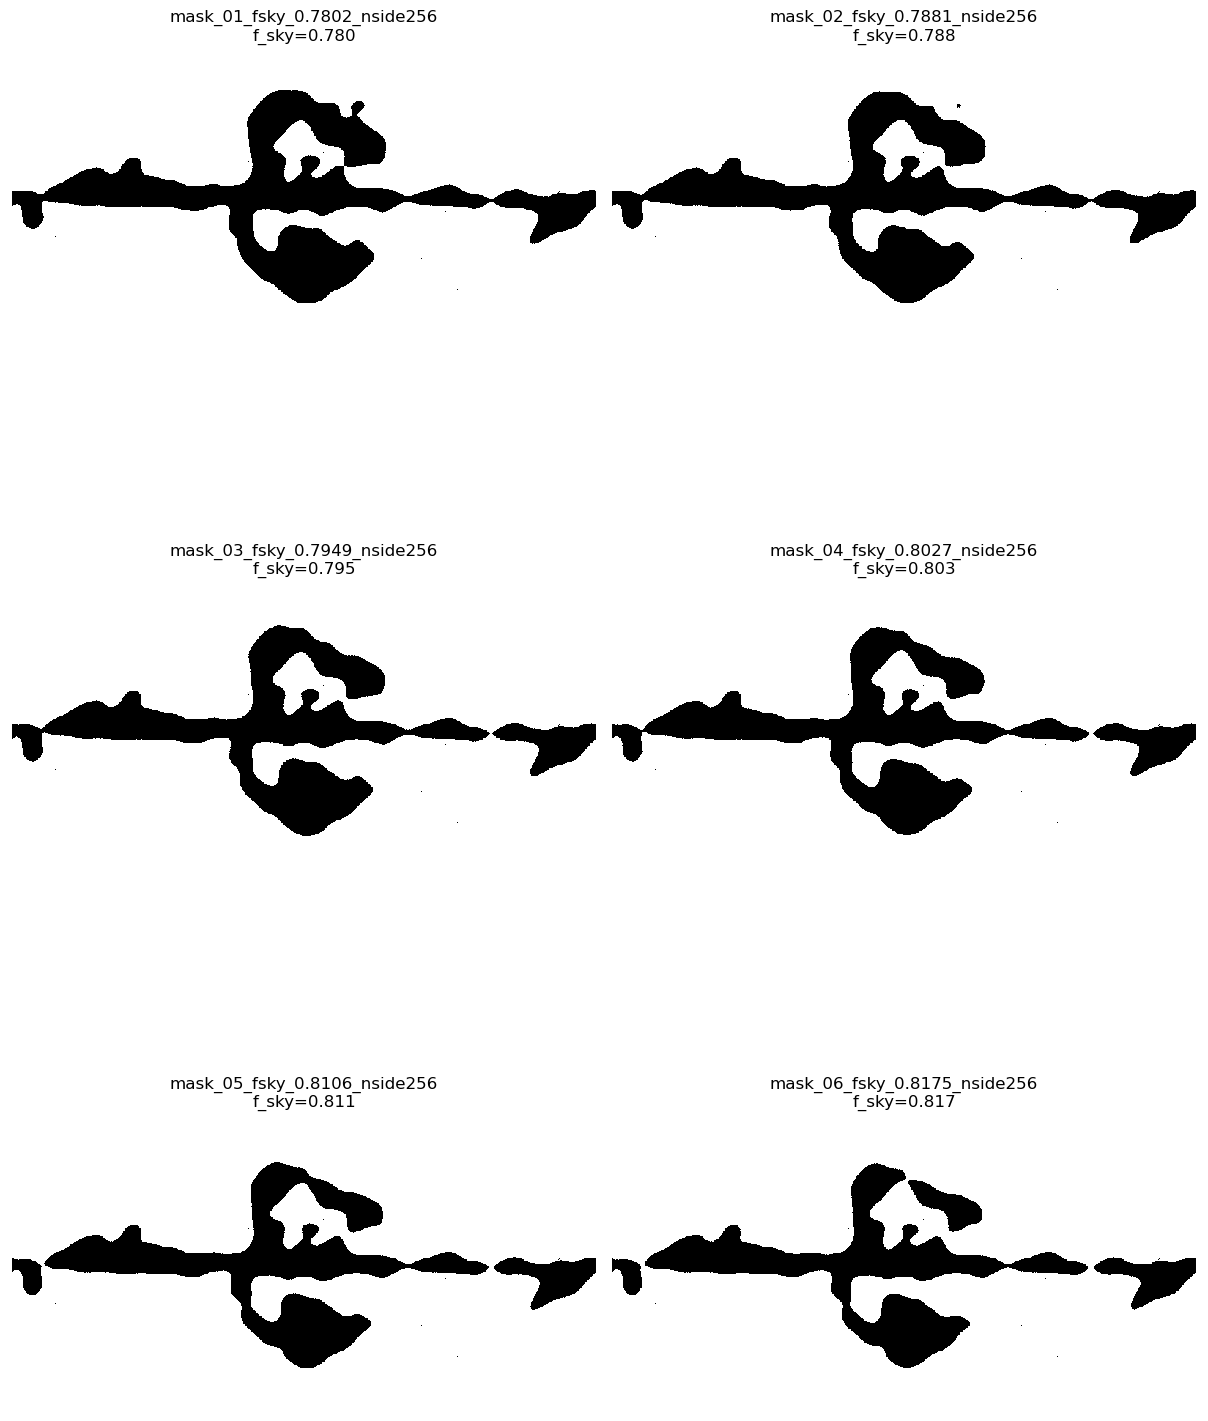

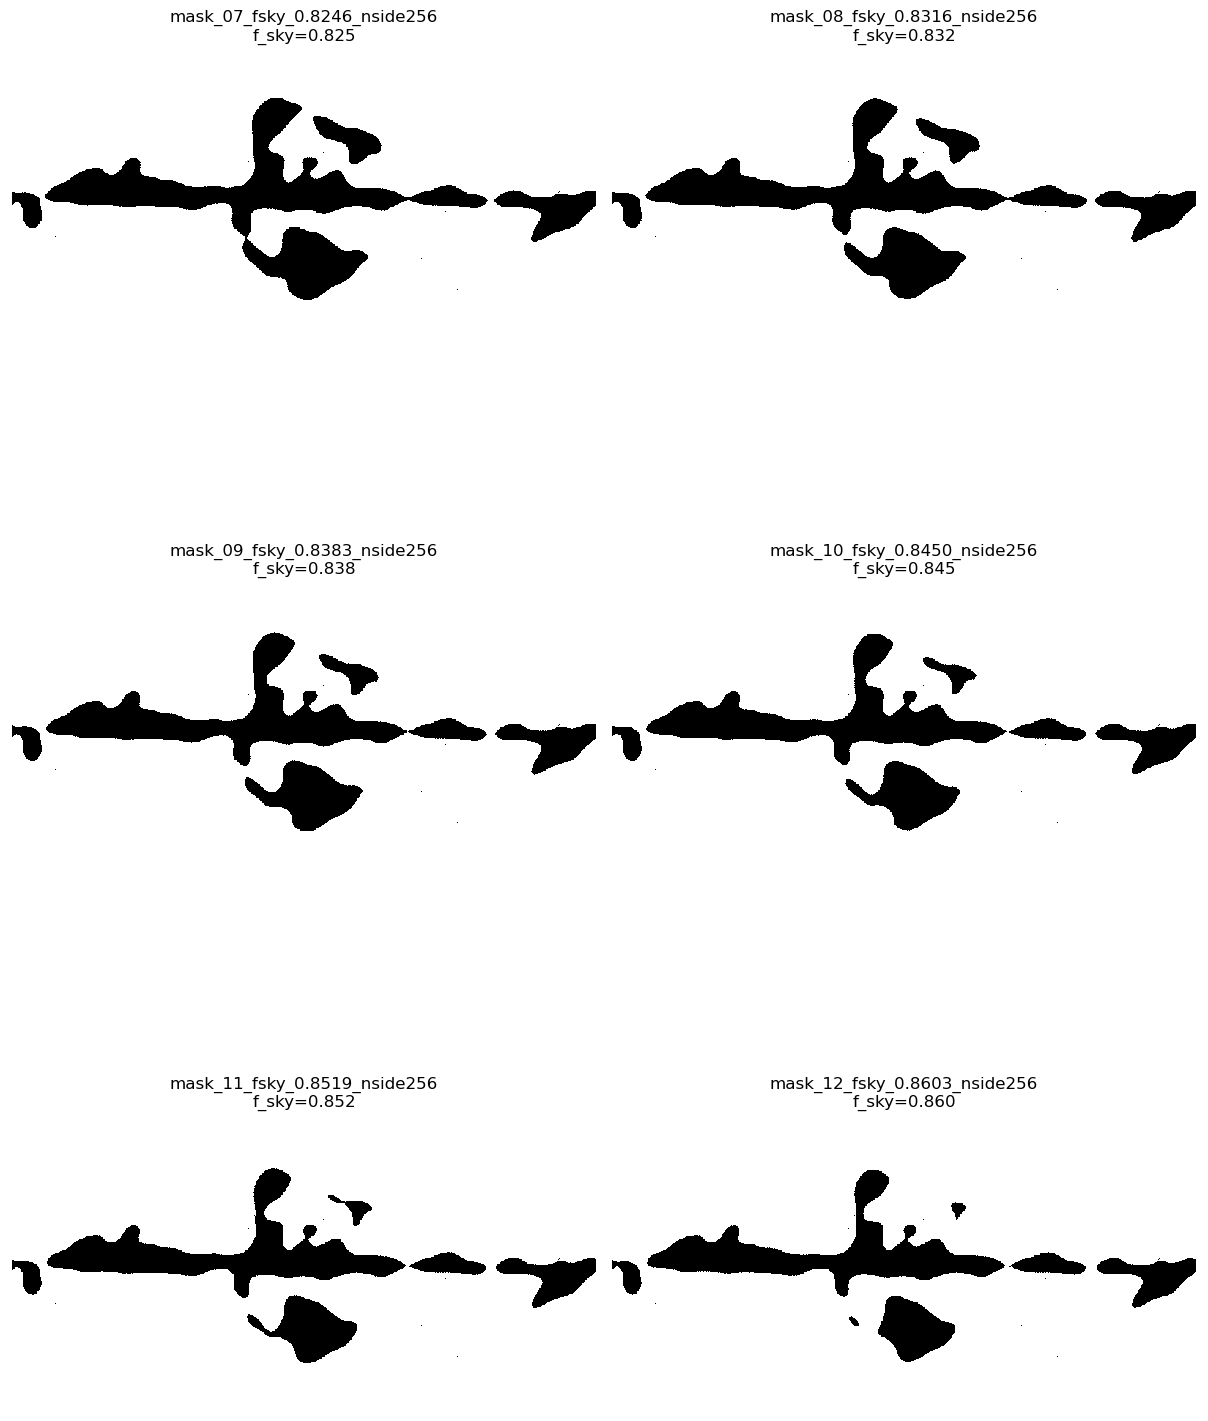

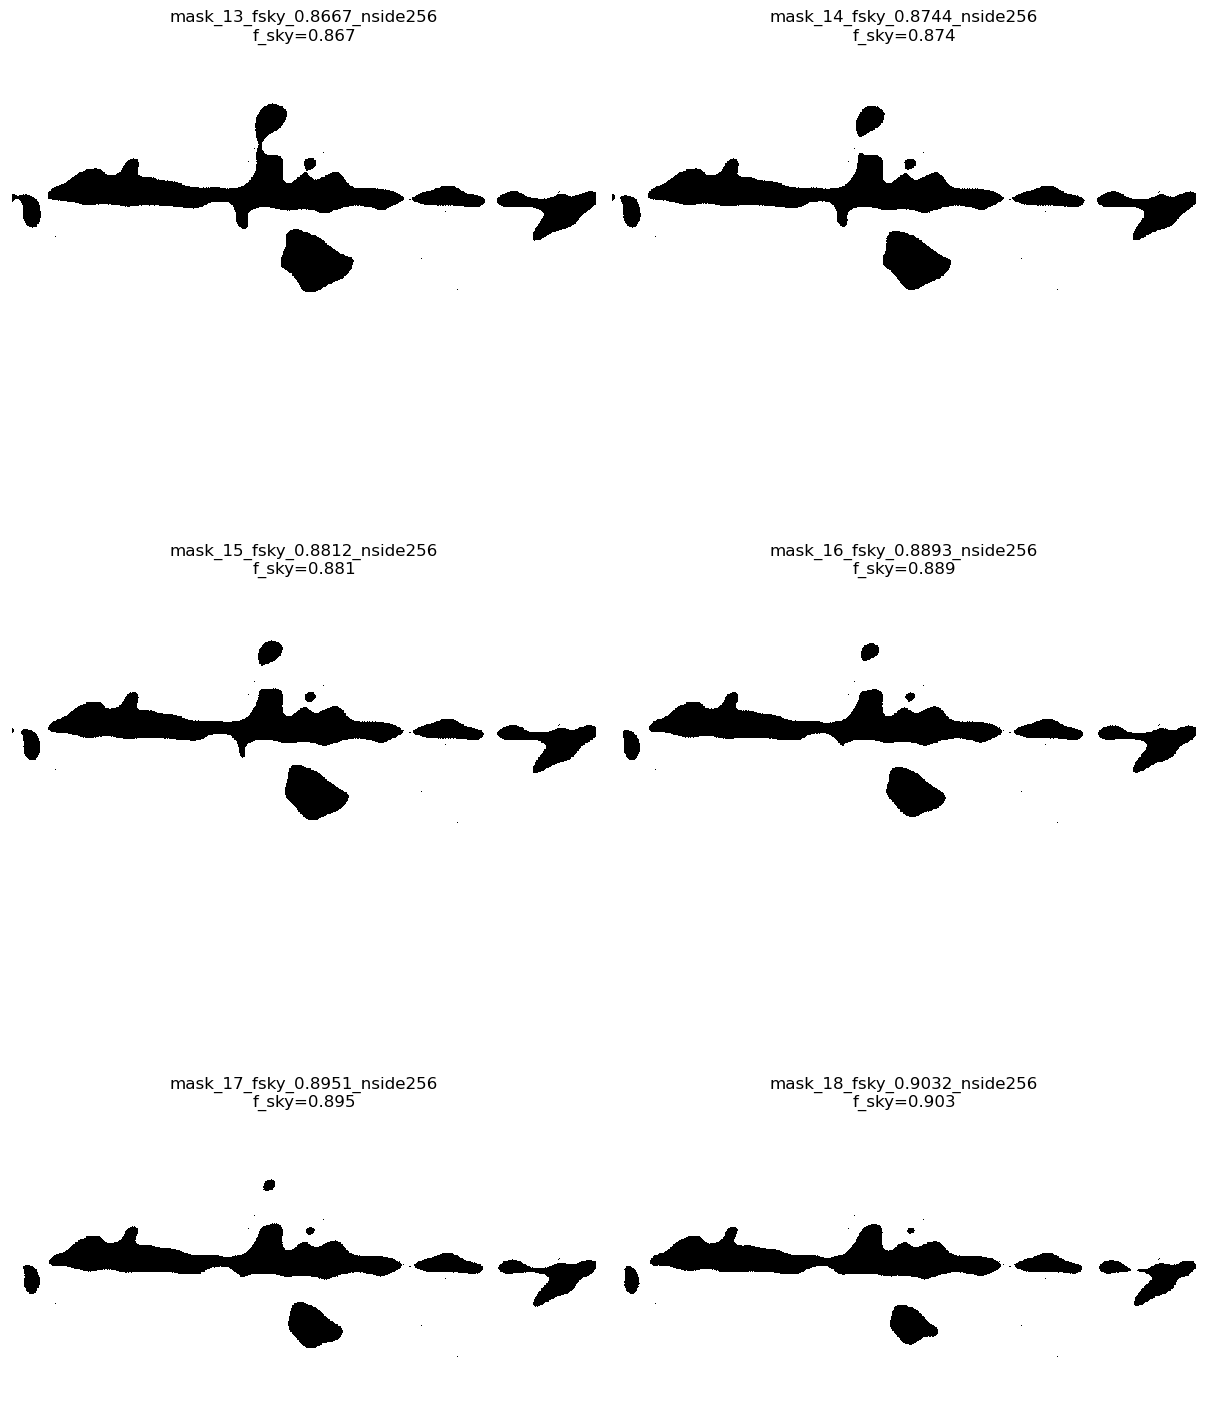

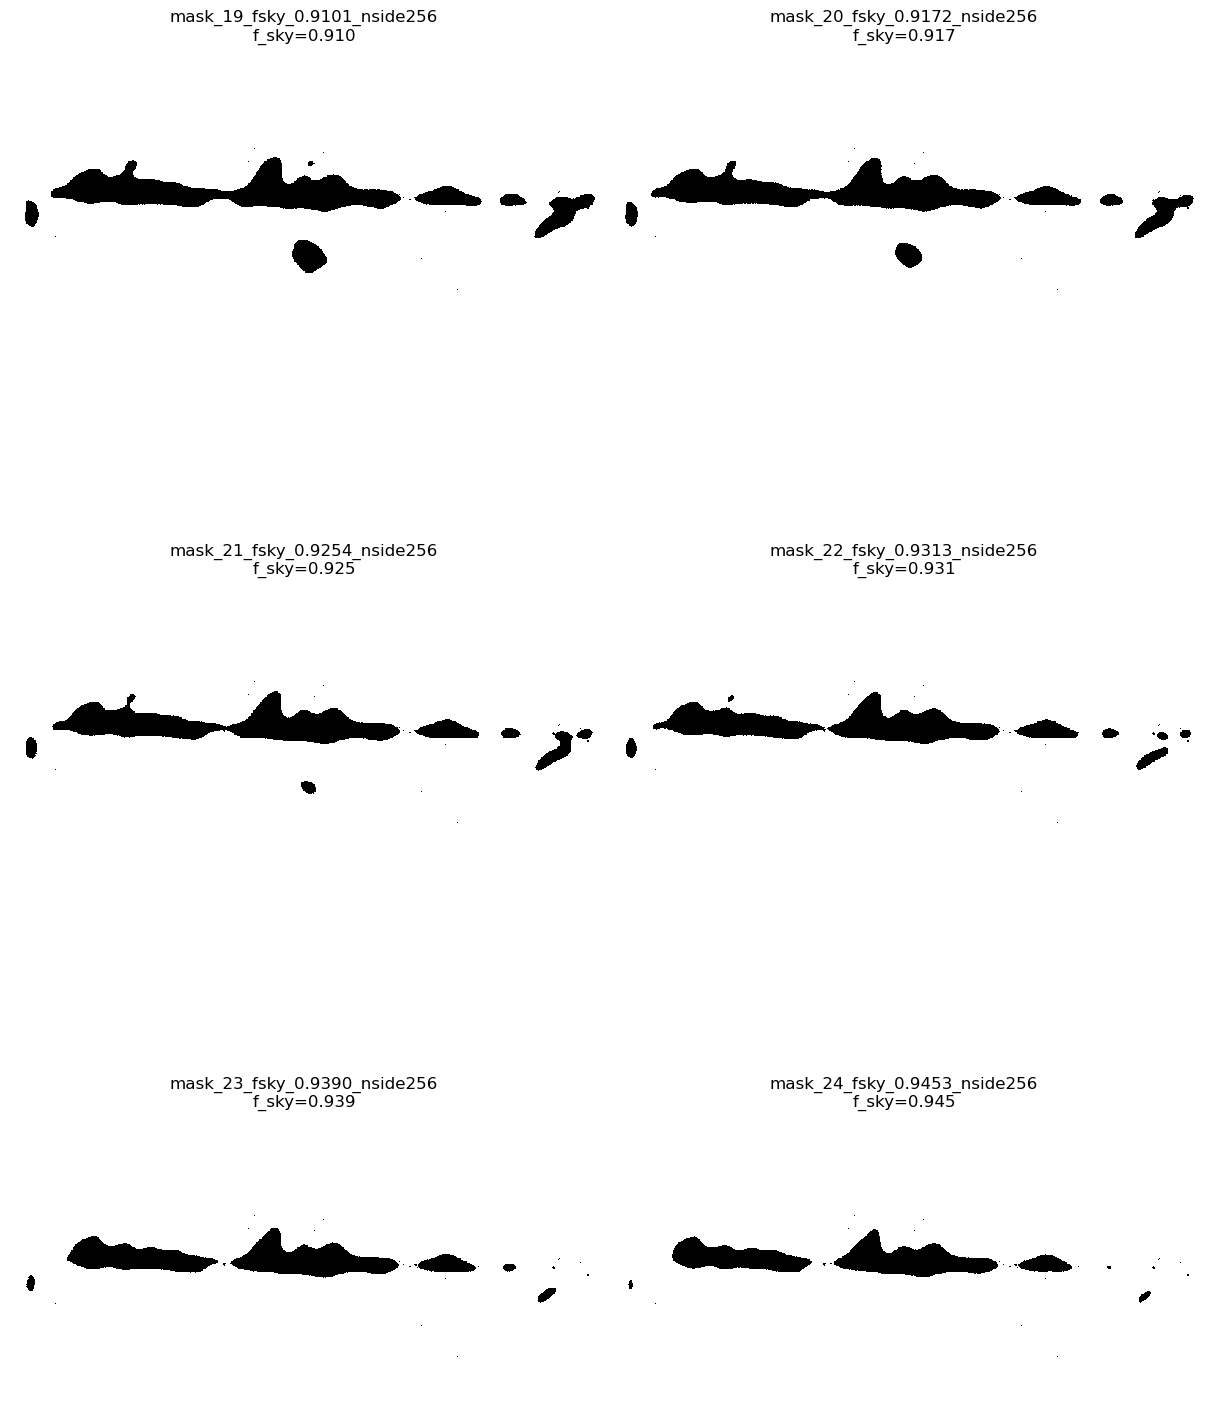

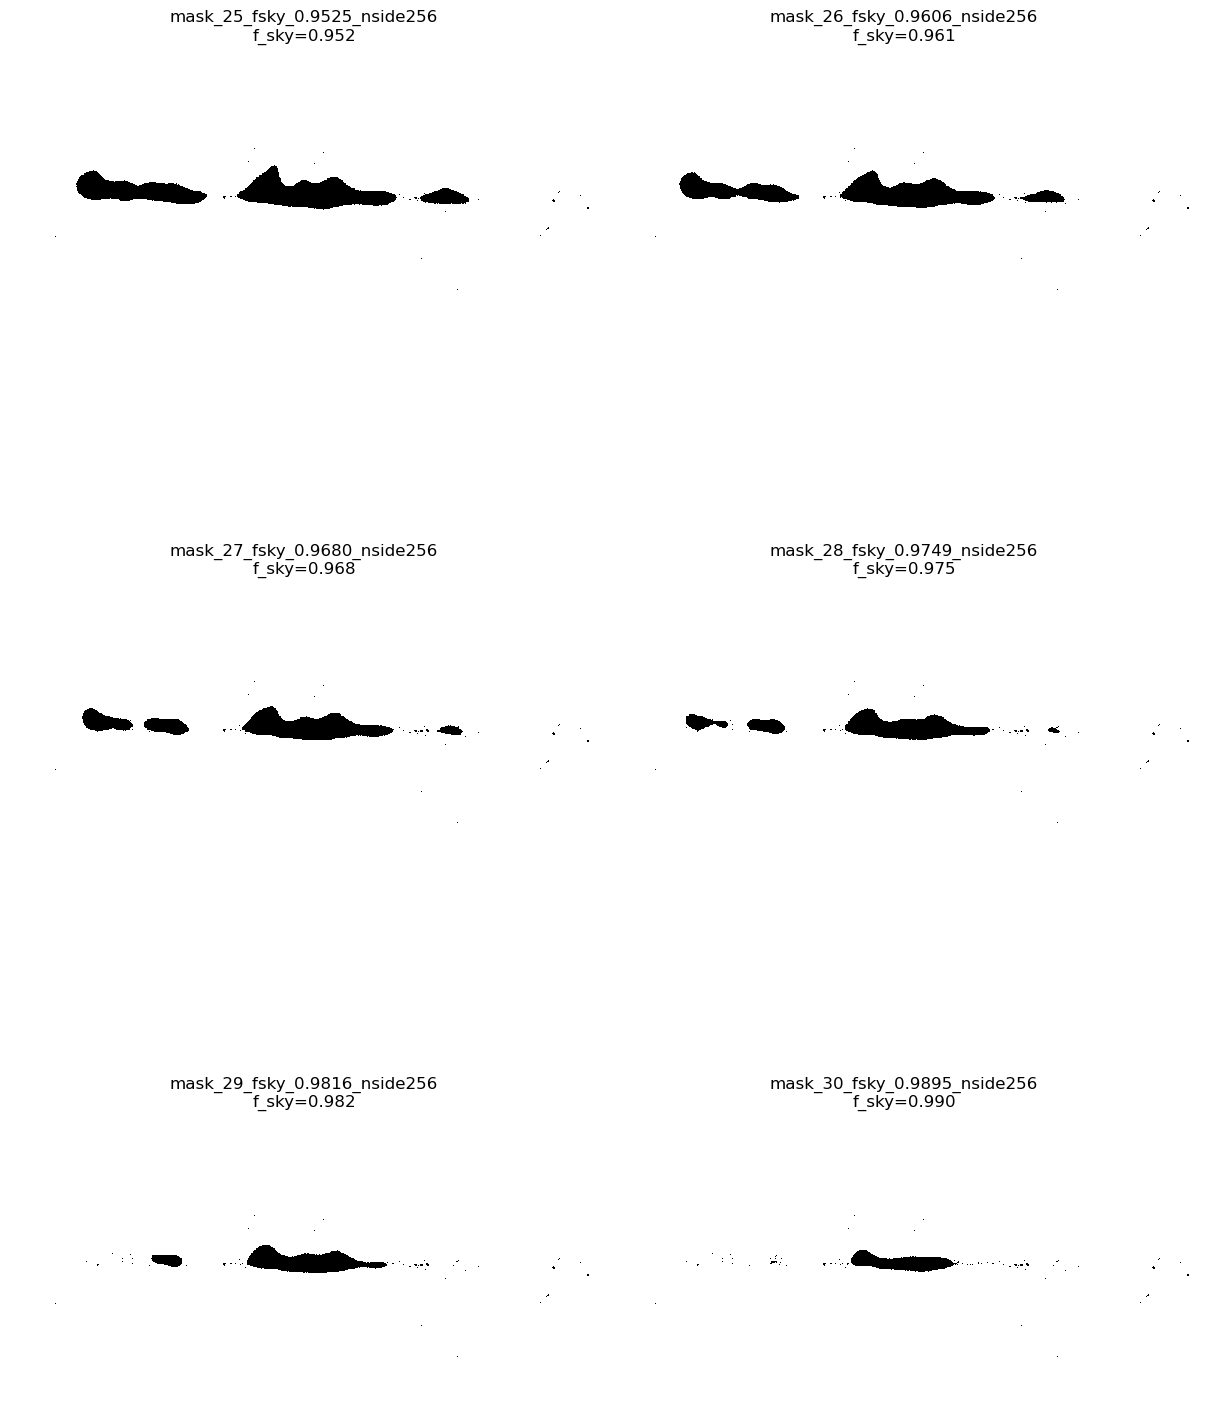

In [2]:
from pathlib import Path
import healpy as hp
import matplotlib.pyplot as plt

folder = Path("/hydrarepo/xluo/circles-in-the-sky/src/masks_fsky_078_to_099")
files = sorted(folder.glob("*.fits"))

# optional: sort by f_sky in filename if present
def get_fsky(file):
    return float(file.stem.split("fsky_")[1].split("_")[0])

files = sorted(files, key=get_fsky)

out = folder / "mask_plots"
out.mkdir(exist_ok=True)

per_page = 6
nrows = 3
ncols = 2

for page in range((len(files) + per_page - 1) // per_page):
    fig = plt.figure(figsize=(12, 16))

    chunk = files[page * per_page : (page + 1) * per_page]

    for i, file in enumerate(chunk, 1):
        mask = hp.read_map(file, verbose=False)
        fsky = mask.mean()

        hp.mollview(
            mask,
            fig=fig.number,
            sub=(nrows, ncols, i),
            title=f"{file.stem}\nf_sky={fsky:.3f}",
            cmap="gray",
            min=0,
            max=1,
            cbar=False,
            notext=True
        )

    plt.tight_layout()
    plt.savefig(out / f"masks_page_{page+1}.png", dpi=200, bbox_inches="tight")
    plt.show()